In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
print(sys.path[0])

/home/benjamin-rodriguez/Desktop/PredictionMarkets


In [8]:
from analysis.time_series import ( 
    to_logit, from_logit, plot_price_and_logit, find_mover_markets, adf_report, adf_summary ,
    plot_acf_pacf, lag1_autocorr_distribution, plot_lag1_distribution, has_real_movement,
    rank_by_predictability, compare_ar_orders, ar_order_survey, get_logit_series, acf
)
    
import numpy as np
import pandas as pd
from db.connection import get_engine, get_conn
    

x = np.linspace(0, 1, 50)
print(f"to_logit({x}) = {to_logit(x)}")

to_logit([0.         0.02040816 0.04081633 0.06122449 0.08163265 0.10204082
 0.12244898 0.14285714 0.16326531 0.18367347 0.20408163 0.2244898
 0.24489796 0.26530612 0.28571429 0.30612245 0.32653061 0.34693878
 0.36734694 0.3877551  0.40816327 0.42857143 0.44897959 0.46938776
 0.48979592 0.51020408 0.53061224 0.55102041 0.57142857 0.59183673
 0.6122449  0.63265306 0.65306122 0.67346939 0.69387755 0.71428571
 0.73469388 0.75510204 0.7755102  0.79591837 0.81632653 0.83673469
 0.85714286 0.87755102 0.89795918 0.91836735 0.93877551 0.95918367
 0.97959184 1.        ]) = [-23.02585093  -3.87120101  -3.15700042  -2.73002911  -2.42036813
  -2.17475172  -1.96944065  -1.79175947  -1.63413053  -1.49165488
  -1.36097655  -1.23969089  -1.12601126  -1.01856958  -0.91629073
  -0.81831032  -0.72391884  -0.63252256  -0.54361545  -0.4567584
  -0.37156356  -0.28768207  -0.20479441  -0.12260232  -0.04082199
   0.04082199   0.12260232   0.20479441   0.28768207   0.37156356
   0.4567584    0.54361545   0.632

    market_id      lo      hi     n
0     1333258  0.1350  0.7950  4138
1     1231857  0.2650  0.7050  4138
2      593974  0.0955  0.7240  4138
3     1068762  0.1900  0.7100  4138
4      676804  0.1800  0.8000  4138
..        ...     ...     ...   ...
335   2196220  0.0950  0.9995   133
336   2070543  0.2860  0.9995   131
337    837734  0.1900  0.9995   126
338    824965  0.2560  0.9995   122
339    837728  0.0020  0.7650   108

[340 rows x 4 columns]


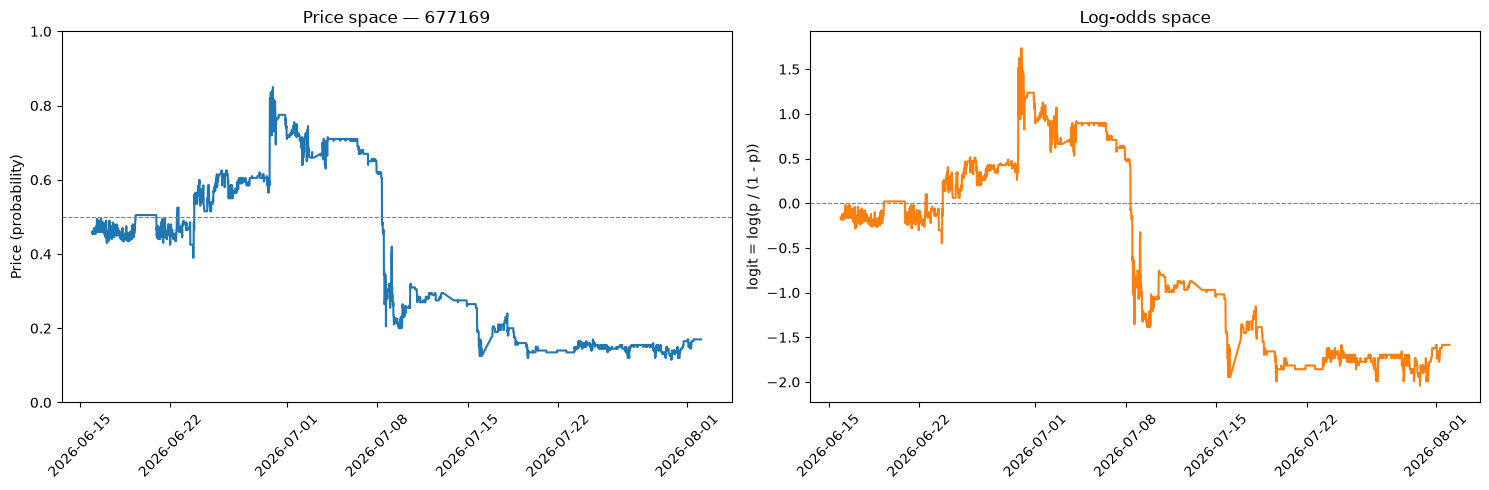

4136 snapshots, price range [0.115, 0.850]


In [3]:
# 3.1 — see the transform
movers = find_mover_markets(limit=1000)
print(movers)
plot_price_and_logit(movers.iloc[7]["market_id"])


In [4]:
def find_name(market_ids: list[str]) -> pd.DataFrame:
    """
    Find markets whose price ranged widely (dipped below `lo` and rose above `hi`),
    with at least min_snaps snapshots. Useful for picking demo markets where the
    logit stretch is visually obvious.
    """
    from db.connection import get_conn
    sql = """
        SELECT title
        FROM markets
        WHERE market_id = ANY(%s)
    """
    with get_conn() as conn:
        return pd.read_sql(sql, conn, params=(market_ids,))
    
print(find_name(["1646000"]))

                                      title
0  Will Donald Trump visit Ireland in 2026?


/tmp/ipykernel_1145242/430794827.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(sql, conn, params=(market_ids,))


In [5]:
print(movers.iloc[7])

market_id    677169
lo            0.115
hi             0.85
n              4136
Name: 7, dtype: object


In [6]:
# 3.2 — stationarity on one market
adf_report(movers.iloc[7]["market_id"])


ADF test — market 677169  (4136 snapshots)
  log-odds LEVELS:
    ADF stat = -0.792   p = 0.8214   -> non-stationary (5% level)
    lags = 26, n = 4109
  log-odds FIRST DIFFERENCES:
    ADF stat = -13.634   p = 0.0000   -> STATIONARY (5% level)
    lags = 25, n = 4109


In [7]:
# 3.2 — confirm the pattern holds across many
sample_ids = movers["market_id"].tolist()   # or a bigger list
adf_summary(sample_ids)
import numpy as np


340 markets tested
  levels stationary:      17.9%
  differences stationary: 92.1%
  (expect: levels mostly NON-stationary, differences mostly stationary)


In [9]:
# get a sample of markets with history
from db.connection import get_conn
import pandas as pd

ids = pd.read_sql("""
        SELECT market_id FROM market_snapshots WHERE mid_price IS NOT NULL
        GROUP BY market_id HAVING COUNT(*) >= 100
        ORDER BY RANDOM() LIMIT 300
    """, get_engine())["market_id"].tolist()

ids = [m for m in ids if has_real_movement(m)]
print(f"{len(ids)} markets with real movement")



90 markets with real movement


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


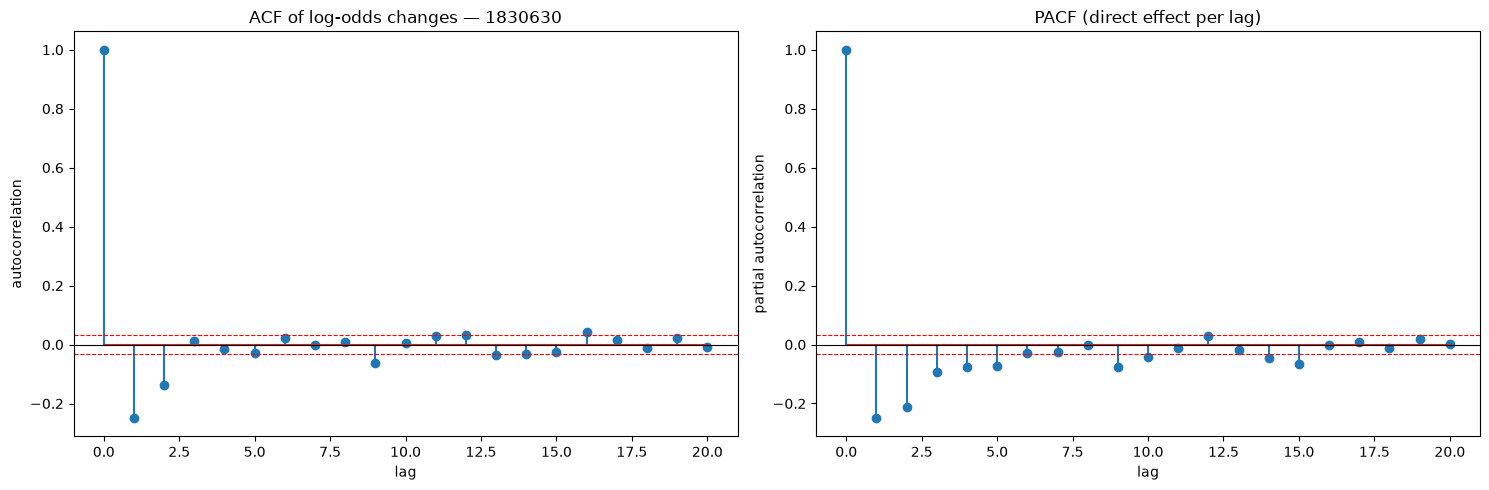

n=3566 changes, significance band = +/- 0.033
lag-1 ACF = -0.249   lag-1 PACF = -0.250


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Deskto

85 markets
  mean lag-1 ACF   = -0.2034
  median lag-1 ACF = -0.2122
  fraction positive = 11.8%  (>50% => momentum tilt, <50% => reversion tilt)
  fraction significantly positive (>+0.033) = 5.9%  [momentum]
  fraction significantly negative (<-0.033) = 85.9%  [reversion / bounce]
  NOTE: short-lag negative autocorr may be bid-ask bounce, not tradeable reversion.


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))


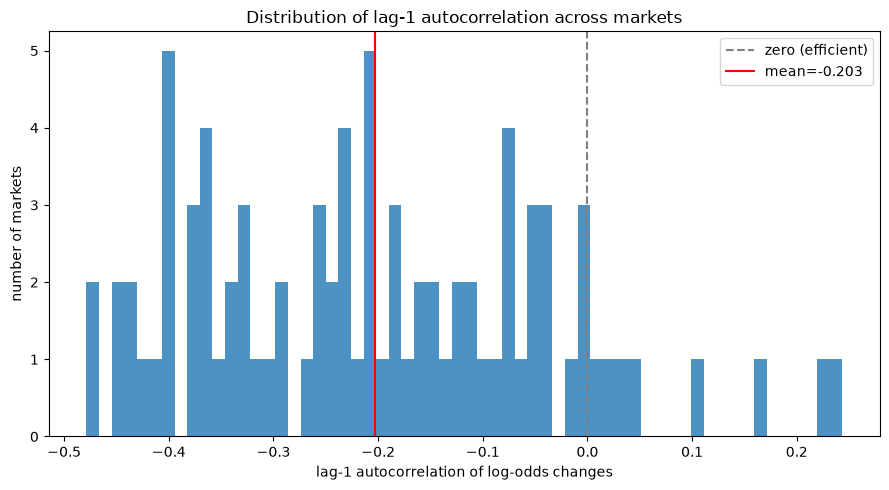

In [5]:
# 3.3 — visual on one market, then the aggregate
plot_acf_pacf(ids[0])
dist = lag1_autocorr_distribution(ids)
plot_lag1_distribution(dist)

In [ ]:
# 3.4 — rank by predictability
ranked = rank_by_predictability(ids)
print(ranked.head(20))

In [ ]:
# does ar(1) suffice, or do markets need more?
ar_order_survey(ids)

In [10]:
# checking stagnant markets
import pandas as pd
from db.connection import get_engine

flat = pd.read_sql("""
    SELECT s.market_id, mk.title, mk.category,
            COUNT(*) AS n_snaps,
            ROUND(MIN(s.mid_price), 4) AS min_price,
            ROUND(MAX(s.mid_price), 4) AS max_price,
            ROUND(MAX(s.mid_price) - MIN(s.mid_price), 4) AS price_range,
            ROUND(AVG(s.mid_price), 4) AS avg_price
    FROM market_snapshots s
    JOIN markets mk ON mk.market_id = s.market_id
    WHERE s.mid_price IS NOT NULL
    GROUP BY s.market_id, mk.title, mk.category
    HAVING COUNT(*) >= 50
        AND (MAX(s.mid_price) - MIN(s.mid_price)) < 0.02
    ORDER BY (MAX(s.mid_price) - MIN(s.mid_price)) ASC, COUNT(*) DESC
    LIMIT 40
""", get_engine())

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)
print(flat.to_string(index=False))

ImportError: cannot import name 'get_engine' from 'db.connection' (/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/connection.py)

In [9]:
# retest on different time frames. 
def autocorr_at_frequency(market_id, freq="1h", min_snaps=50):
    hist = get_logit_series(market_id, min_snaps=min_snaps)
    if hist.empty:
        return None
    s = hist.set_index("snapshot_at")["logit"].resample(freq).last().dropna()
    if len(s) < 20:
        return None
    d = np.diff(s.values)
    if np.std(d) < 1e-8:
        return None
    return acf(d, nlags=1, fft=True)[1]

for mid in ids[:10]:
    a15 = autocorr_at_frequency(mid, "15min")
    a1h = autocorr_at_frequency(mid, "1h")
    a4h = autocorr_at_frequency(mid, "4h")
    print(f"{mid}: 15min={a15}, 1h={a1h}, 4h={a4h}")

/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Deskto

1830630: 15min=-0.2480466703848667, 1h=-0.2876570794998588, 4h=-0.18653752734168383
799876: 15min=-0.3661427232158591, 1h=-0.28895177211016243, 4h=-0.1363088361129416


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Deskto

1283408: 15min=-0.25721138605551236, 1h=-0.21985572376085163, 4h=-0.3053283929652727
2000273: 15min=-0.11764846648090904, 1h=-0.029844561437477067, 4h=-0.1015615121627815
1032420: 15min=-0.07111417510681887, 1h=-0.04445605031785847, 4h=0.04873872818375331


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Deskto

1459636: 15min=-0.09340549762613426, 1h=-0.10786518245967623, 4h=-0.39847189494375146
1447976: 15min=-0.45072599955233095, 1h=-0.4526079933208103, 4h=-0.380792461269357
2108920: 15min=-0.3672987005670686, 1h=-0.23685083061420648, 4h=0.07020831940893307


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Deskto

789957: 15min=0.004117357171609424, 1h=-0.006585061607687255, 4h=-0.11417624330874736
2168308: 15min=-0.20043187022564146, 1h=-0.01894398818274757, 4h=-0.05169692204317109


/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
/home/benjamin-rodriguez/Desktop/PredictionMarkets/db/queries.py:215: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn, params=(market_ids,))
